In [49]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ['GROQ_API_KEY']=os.getenv("GROQ_API_KEY")

In [50]:
from langchain_groq import ChatGroq

llm=ChatGroq(model='openai/gpt-oss-120b')

In [51]:
from langchain_community.document_loaders import PyPDFLoader

loader=PyPDFLoader(r'E:\chatbot\rag\Azra_Patvi_Data_Scientist_Resume_v2.pdf')
data=loader.load()

In [53]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter=RecursiveCharacterTextSplitter(chunk_size=1000,chunk_overlap=100)
splitted_data=splitter.split_documents(data)

In [55]:
from langchain_community.embeddings import HuggingFaceEmbeddings

embeddings=HuggingFaceEmbeddings(
    model_name="all-MiniLM-L6-v2"
)
embeddings

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1912.41it/s]


HuggingFaceEmbeddings(client=SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
), model_name='all-MiniLM-L6-v2', cache_folder=None, model_kwargs={}, encode_kwargs={}, multi_process=False, show_progress=False)

In [56]:
from langchain_community.vectorstores import FAISS

vector_store=FAISS.from_documents(
    splitted_data,
    embedding=embeddings
)

In [57]:
vector_store

In [58]:
retriever=vector_store.as_retriever(search_kwargs={"k": 5})

In [60]:
#rag tool creation

from langchain_core.tools import tool

@tool
def rag_tool(query):
    """this is a rag tool to retrieve the details from the provided document. retrieve the relevant information from the document"""

    result=retriever.invoke(query)

    page_content=[doc.page_content for doc in result]
    metadata=[doc.metadata for doc in result]

    return {
        "query":query,
        "page_content":page_content,
        "metadata":metadata
    }

In [61]:
tools=[rag_tool]

llm_with_tool=llm.bind_tools(tools)

In [62]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000018835506BA0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001883C71F710>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'rag_tool', 'description': 'this is a rag tool to retrieve the details from the provided d

In [63]:
from typing import Annotated

from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages:Annotated[list,add_messages]

In [ ]:
# build a graph
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver

graph_builder=StateGraph(State)

#node functionality
def chatbot(state:State):
    return {
        "messages":[
            llm_with_tool.invoke(state['messages'])
        ]
    }

graph_builder.add_node('chatbot',chatbot)
graph_builder.add_node('tools',ToolNode(tools))

graph_builder.add_edge(START,'chatbot')
graph_builder.add_conditional_edges('chatbot',tools_condition)
graph_builder.add_edge('tools','chatbot')

memory=InMemorySaver()
graph=graph_builder.compile(checkpointer=memory)

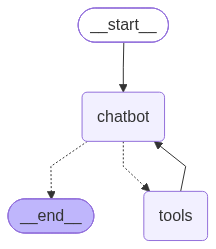

In [65]:
#visualize the graph

from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [66]:
res=graph.invoke({"messages":"i saw that she has mentioned the projects on the resume list those projects"})

In [67]:
res["messages"][-1].pretty_print()

================================== Ai Message ==================================

Here are the projects that Azra Patvi highlights on her résumé (the ones listed under the **PROJECTS** section, plus the notable college‑management system she built while working as COO/Developer).

| # | Project (link) | Brief description | Technologies used |
|---|----------------|-------------------|-------------------|
| 1 | **AI‑Powered Virtual Interviewer** | An AI interview system that authenticates the candidate with facial‑recognition at login, monitors the webcam for extra/missing faces during the interview, generates domain‑specific questions with Gemini, evaluates each answer, and produces written & spoken feedback plus a downloadable PDF report stored in MongoDB. | Python, DeepFace, OpenCV, Gemini API, MongoDB |
| 2 | **Dr. One (Multi‑Model Medical Backend)** | A FastAPI‑based backend that serves four separate medical‑image models: a brain‑MRI CNN (≈ 91.5 % test accuracy), an ovarian‑ultrasou